In [1]:
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
dataset = pd.read_csv('dataset.csv')

In [3]:
dataset.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,class
0,0.368684,0.141667,0.045455,0.184681,0.223514,0.071659,0.870079,0.913386,0.582677,0.875366,...,0,0,0,0,0,0,0,0,0,5
1,0.365683,0.155556,0.030303,0.151754,0.215762,0.054798,0.866142,0.925197,0.594488,0.867838,...,0,0,0,0,0,0,0,0,0,5
2,0.472736,0.386111,0.136364,0.191840,0.307494,0.446817,0.921260,0.937008,0.531496,0.853339,...,0,0,0,0,0,0,0,0,0,2
3,0.463232,0.430556,0.272727,0.173228,0.375969,0.434172,0.937008,0.937008,0.480315,0.865886,...,0,0,0,0,0,0,0,0,0,2
4,0.368184,0.125000,0.030303,0.109520,0.222222,0.054939,0.866142,0.921260,0.590551,0.860449,...,0,0,0,0,0,0,0,0,0,5


In [4]:
print(dataset.columns)

Index(['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology',
       'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways',
       'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
       'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1',
       'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4',
       'Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5',
       'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10',
       'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14',
       'Soil_Type15', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18',
       'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22',
       'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26',
       'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30',
       'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34',
       'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38',
       'Soil_Type39', 'Soil_Type40

In [5]:
df2 = dataset[["Elevation","Aspect","Slope","Horizontal_Distance_To_Hydrology","Vertical_Distance_To_Hydrology","Horizontal_Distance_To_Roadways","Horizontal_Distance_To_Fire_Points","Hillshade_9am","Hillshade_Noon","Hillshade_3pm"]]
labels = dataset["class"]
df2.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Horizontal_Distance_To_Fire_Points,Hillshade_9am,Hillshade_Noon,Hillshade_3pm
0,0.368684,0.141667,0.045455,0.184681,0.223514,0.071659,0.875366,0.870079,0.913386,0.582677
1,0.365683,0.155556,0.030303,0.151754,0.215762,0.054798,0.867838,0.866142,0.925197,0.594488
2,0.472736,0.386111,0.136364,0.191840,0.307494,0.446817,0.853339,0.921260,0.937008,0.531496
3,0.463232,0.430556,0.272727,0.173228,0.375969,0.434172,0.865886,0.937008,0.937008,0.480315
4,0.368184,0.125000,0.030303,0.109520,0.222222,0.054939,0.860449,0.866142,0.921260,0.590551


In [6]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df2)

pca = PCA(n_components=2)
pca_array = pca.fit_transform(scaled_data)

component_names = [f"PC{i+1}" for i in range(pca_array.shape[1])]
df_pca = pd.DataFrame(pca_array, columns=component_names, index=df2.index)

df_plot = df_pca.join(labels)

df_plot = (
    df_pca.join(labels)
    .groupby("class", group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(len(group), 1300),
            random_state=42
        ).assign(**{"class": group.name}),
        include_groups=False
    )
    .reset_index(drop=True)
)

In [7]:
df_plot.head()
# shuffle df_plot
df_plot = df_plot.sample(frac=1, random_state=42).reset_index(drop=True) 

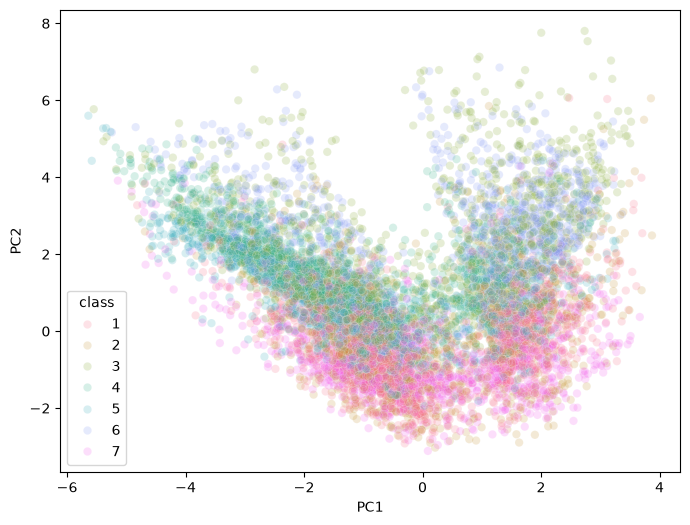

In [8]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df_plot,
    x="PC1",
    y="PC2",
    hue="class",
    palette=sns.color_palette("husl", 7),
    alpha=0.20
            )
plt.show()

In [9]:
# Re-run PCA with three principal components
pca_3 = PCA(n_components=3)
pca_3_array = pca_3.fit_transform(scaled_data)

df_pca_3 = pd.DataFrame(
    pca_3_array,
    columns=["PC1", "PC2", "PC3"],
    index=df2.index,
)

# Keep the class labels and sample up to 1,000 points per class
df_plot_3d = df_pca_3.join(labels)

df_plot_3d = (
    df_plot_3d.groupby("class", group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(len(group), 1000),
            random_state=42,
        ).assign(**{"class": group.name}),
        include_groups=False,
    )
    .reset_index(drop=True)
)

# Interactive 3D PCA chart
import plotly.express as px

fig = px.scatter_3d(
    df_plot_3d,
    x="PC1",
    y="PC2",
    z="PC3",
    color="class",
    title="Interactive 3D PCA Plot",
    labels={
        "PC1": "Principal Component 1",
        "PC2": "Principal Component 2",
        "PC3": "Principal Component 3",
        "class": "Class",
    },
)

fig.update_traces(marker={"size": 4})
fig.show(renderer="browser")

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [11]:
# Choose and split the dataset

df_ml = df_plot

X = df_ml.drop(columns=["class"])
y = df_ml["class"]

# X = df2
# y = labels

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Chosen dataset size:",len(df_ml))
df_ml.head()

Chosen dataset size: 9100


,PC1,PC2,class
0,-1.222076,1.455771,5
1,-1.204479,-0.695717,7
2,2.395211,2.415613,6
3,0.608172,0.645240,4
4,0.269796,0.665715,6


In [12]:
# Scale the data

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
# Initialize and fit the SVM model

model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [14]:
# Run inference on the test set

y_pred = model.predict(X_test_scaled)
print(f"Accuracy: {accuracy_score(y_test,y_pred):.4f}")
print("\nClassification Report:\n",classification_report(y_test,y_pred))

Accuracy: 0.3467

Classification Report:
               precision    recall  f1-score   support

           1       0.33      0.56      0.41       262
           2       0.35      0.03      0.06       266
           3       0.49      0.07      0.13       272
           4       0.35      0.63      0.45       243
           5       0.27      0.48      0.35       246
           6       0.39      0.44      0.41       244
           7       0.49      0.26      0.34       287

    accuracy                           0.35      1820
   macro avg       0.38      0.36      0.31      1820
weighted avg       0.38      0.35      0.30      1820



In [35]:
import xgboost as xgb
model_xgb = xgb.XGBClassifier(
    n_estimators = 100,
    max_depth = 5,
    learning_rate = 0.10,
    objective='multi:softmax',
    random_state=42
)

y_train_xgb = y_train - 1
y_test_xgb = y_test - 1

model_xgb.fit(X_train_scaled, y_train_xgb)

y_pred_xgb = model_xgb.predict(X_test_scaled)

accuracy = accuracy_score(y_test_xgb, y_pred_xgb)
print(f"Accuracy: {accuracy * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_xgb, y_pred_xgb))

Accuracy: 37.64%

Classification Report:
              precision    recall  f1-score   support

           0       0.37      0.46      0.41       262
           1       0.28      0.14      0.19       266
           2       0.37      0.11      0.17       272
           3       0.37      0.76      0.50       243
           4       0.30      0.35      0.32       246
           5       0.40      0.39      0.40       244
           6       0.52      0.45      0.48       287

    accuracy                           0.38      1820
   macro avg       0.37      0.38      0.35      1820
weighted avg       0.37      0.38      0.35      1820

